# M1a: pseudobulk samples and variance partitioning

Contract: `audit/contracts/M1a_pseudobulk.md`. Pseudobulk logic: `src/m1a_pseudobulk.py` (tested); variance partitioning: `R/m1a_varpart.R`.
This notebook only reads their output files and shows them. Nothing here drops a sample; outlier samples are shown with distances, **no automatic flag** (decision, Wave 1).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160, "display.max_columns", 20)
PROC = ROOT / "data/processed"
FILES = ["m1a_counts.csv", "m1a_samples.csv", "m1a_counts_no_outliers.csv", "m1a_samples_no_outliers.csv",
         "m1a_varpart.csv", "m1a_varpart_vst.csv", "m1a_varpart_fits.csv", "m1a_cancor.csv"]
MIN_BASEMEAN = 1  # the R script was run with this value (DE gene filter, baseMean > 1)
TERMS = ["donor", "condition", "log_n_cells", "log_total_counts", "Residuals"]
# Condition labels come from the M0 output (uns), never hardcoded
_m0 = ad.read_h5ad(ROOT / "data/processed/m0_cells.h5ad", backed="r")
CONTROL, TREATMENT = str(_m0.uns["control"]), str(_m0.uns["treatment"])
_m0.file.close()
CONDS = [CONTROL, TREATMENT]
COND_COLORS = {CONTROL: "#1b74ac", TREATMENT: "#dd1b26"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

samples = pd.read_csv(PROC / "m1a_samples.csv")
varpart = pd.read_csv(PROC / "m1a_varpart.csv")
vst = pd.read_csv(PROC / "m1a_varpart_vst.csv")
fits = pd.read_csv(PROC / "m1a_varpart_fits.csv")
CELL_TYPES = sorted(samples["cell_type"].unique())

## 1. Every output file: shape, head and tail

In [2]:
for f in FILES:
    df = pd.read_csv(PROC / f, index_col=0 if "counts" in f else None)
    print(f"{f}: {df.shape[0]} rows × {df.shape[1]} columns")
    display(df.head()); display(df.tail())

m1a_counts.csv: 15701 rows × 128 columns


,B cells|patient_1015|ctrl,B cells|patient_1015|stim,B cells|patient_1016|ctrl,B cells|patient_1016|stim,B cells|patient_101|ctrl,B cells|patient_101|stim,B cells|patient_1039|ctrl,B cells|patient_1039|stim,B cells|patient_107|ctrl,B cells|patient_107|stim,...,NK cells|patient_1039|ctrl,NK cells|patient_1039|stim,NK cells|patient_107|ctrl,NK cells|patient_107|stim,NK cells|patient_1244|ctrl,NK cells|patient_1244|stim,NK cells|patient_1256|ctrl,NK cells|patient_1256|stim,NK cells|patient_1488|ctrl,NK cells|patient_1488|stim
gene,,,,,,,,,,,,,,,,,,,,,
AL627309.1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
RP11-206L10.2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
RP11-206L10.9,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
FAM87B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
LINC00115,1,1,1,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,1,4,0


,B cells|patient_1015|ctrl,B cells|patient_1015|stim,B cells|patient_1016|ctrl,B cells|patient_1016|stim,B cells|patient_101|ctrl,B cells|patient_101|stim,B cells|patient_1039|ctrl,B cells|patient_1039|stim,B cells|patient_107|ctrl,B cells|patient_107|stim,...,NK cells|patient_1039|ctrl,NK cells|patient_1039|stim,NK cells|patient_107|ctrl,NK cells|patient_107|stim,NK cells|patient_1244|ctrl,NK cells|patient_1244|stim,NK cells|patient_1256|ctrl,NK cells|patient_1256|stim,NK cells|patient_1488|ctrl,NK cells|patient_1488|stim
gene,,,,,,,,,,,,,,,,,,,,,
C21orf58,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
PCNT,2,1,0,1,0,0,1,1,0,0,...,0,1,0,0,0,0,4,2,1,1
DIP2A,2,1,1,1,0,0,0,0,1,0,...,0,1,0,1,1,1,9,3,0,3
S100B,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,6,2,0,0
PRMT2,47,28,9,8,14,12,0,3,0,9,...,3,1,13,20,21,23,53,57,9,16


m1a_samples.csv: 128 rows × 7 columns


,sample,cell_type,donor,condition,n_cells,total_counts,kept
0,B cells|patient_1015|ctrl,B cells,patient_1015,ctrl,453,552462,True
1,B cells|patient_1015|stim,B cells,patient_1015,stim,341,436691,True
2,B cells|patient_1016|ctrl,B cells,patient_1016,ctrl,126,155808,True
3,B cells|patient_1016|stim,B cells,patient_1016,stim,116,140336,True
4,B cells|patient_101|ctrl,B cells,patient_101,ctrl,107,127162,True


...

,cell_type,fit_type_used
0,B cells,parametric
1,CD14+ Monocytes,parametric
2,CD4 T cells,parametric
3,CD8 T cells,parametric
4,Dendritic cells,parametric


,cell_type,fit_type_used
3,CD8 T cells,parametric
4,Dendritic cells,parametric
5,FCGR3A+ Monocytes,parametric
6,Megakaryocytes,parametric
7,NK cells,parametric


m1a_cancor.csv: 128 rows × 4 columns


,cell_type,term1,term2,cancor
0,B cells,donor,donor,1.000000e+00
1,B cells,condition,donor,2.106689e-16
2,B cells,log_n_cells,donor,9.883549e-01
3,B cells,log_total_counts,donor,9.799038e-01
4,B cells,donor,condition,2.106689e-16


,cell_type,term1,term2,cancor
123,NK cells,log_total_counts,log_n_cells,0.994681
124,NK cells,donor,log_total_counts,0.975336
125,NK cells,condition,log_total_counts,0.189121
126,NK cells,log_n_cells,log_total_counts,0.994681
127,NK cells,log_total_counts,log_total_counts,1.000000


## 2. Sample table
Cells per sample (rows: cell type; columns: donor × condition). A1: a donor is dropped from a cell type (both conditions) if either condition has < 10 cells. Dropped samples are listed below.

In [3]:
display(samples.pivot_table(index="cell_type", columns=["donor", "condition"], values="n_cells", aggfunc="sum"))
print("Dropped samples (kept = False):")
display(samples[~samples["kept"]])
summary = samples.groupby("cell_type").agg(samples=("sample", "size"), kept=("kept", "sum"),
                                           paired_donors=("donor", lambda d: d[samples.loc[d.index, "kept"]].nunique()),
                                           cells_kept=("n_cells", lambda n: n[samples.loc[n.index, "kept"]].sum()))
display(summary)
print("Total samples:", len(samples), "| kept:", int(samples["kept"].sum()),
      "| n_cells sum:", int(samples["n_cells"].sum()), "| in kept samples:", int(samples.loc[samples["kept"], "n_cells"].sum()))
clean = pd.read_csv(PROC / "m1a_samples_no_outliers.csv")
print("No-outlier variant: samples", len(clean), "| kept", int(clean["kept"].sum()), "| n_cells sum", int(clean["n_cells"].sum()),
      "| samples whose kept status differs from the main run:",
      int((clean.set_index("sample")["kept"] != samples.set_index("sample")["kept"]).sum()))

donor             patient_101      patient_1015      patient_1016      patient_1039      patient_107      patient_1244      patient_1256      patient_1488  \
condition                ctrl stim         ctrl stim         ctrl stim         ctrl stim        ctrl stim         ctrl stim         ctrl stim         ctrl   
cell_type                                                                                                                                                    
B cells                   107  135          453  341          126  116           26   39          44   54          116   93          216  208          218   
CD14+ Monocytes           202  253          779  671          369  329          112  150         209  169          415  290          390  375          294   
CD4 T cells               293  382          848  734          422  353          182  272         158  186         1068  854         1001  954         1182   
CD8 T cells                74  105          179  133          536  489           26   29          20   15           58   32          131  112           58   
Dendritic cells            21   34           30   30           19   15            9   17           8   14           47   33           26   32           43   
FCGR3A+ Monocytes          80  144          252  228          115  128           31   43          32   37           56   35           69   97          101   
Megakaryocytes             11    9           20   20            8   10            4   11           6    4           14   13           14   17           18   
NK cells                   70  104          177  195          128  195           18   23          40   46          105  114          261  231          116   

donor                    
condition          stim  
cell_type                
B cells             279  
CD14+ Monocytes     348  
CD4 T cells        1484  
CD8 T cells          43  
Dendritic cells      54  
FCGR3A+ Monocytes   144  
Megakaryocytes       29  
NK cells            168

Dropped samples (kept = False):


,sample,cell_type,donor,condition,n_cells,total_counts,kept
70,Dendritic cells|patient_1039|ctrl,Dendritic cells,patient_1039,ctrl,9,30796,False
71,Dendritic cells|patient_1039|stim,Dendritic cells,patient_1039,stim,17,46149,False
72,Dendritic cells|patient_107|ctrl,Dendritic cells,patient_107,ctrl,8,28548,False
73,Dendritic cells|patient_107|stim,Dendritic cells,patient_107,stim,14,47099,False
98,Megakaryocytes|patient_1016|ctrl,Megakaryocytes,patient_1016,ctrl,8,8245,False
99,Megakaryocytes|patient_1016|stim,Megakaryocytes,patient_1016,stim,10,11104,False
100,Megakaryocytes|patient_101|ctrl,Megakaryocytes,patient_101,ctrl,11,19721,False
101,Megakaryocytes|patient_101|stim,Megakaryocytes,patient_101,stim,9,15971,False
102,Megakaryocytes|patient_1039|ctrl,Megakaryocytes,patient_1039,ctrl,4,5434,False
103,Megakaryocytes|patient_1039|stim,Megakaryocytes,patient_1039,stim,11,11828,False


,samples,kept,paired_donors,cells_kept
cell_type,,,,
B cells,16,16,8,2571
CD14+ Monocytes,16,16,8,5355
CD4 T cells,16,16,8,10373
CD8 T cells,16,16,8,2040
Dendritic cells,16,12,6,384
FCGR3A+ Monocytes,16,16,8,1592
Megakaryocytes,16,8,4,145
NK cells,16,16,8,1991


Total samples: 128 | kept: 116 | n_cells sum: 24562 | in kept samples: 24451
No-outlier variant: samples 128 | kept 116 | n_cells sum 24048 | samples whose kept status differs from the main run: 0


## 3. Technical covariates vs condition (kept samples)
`n_cells` and `total_counts` per sample, control vs stimulated, one line per donor. These are the two covariates in the variance-partitioning model. (10x run = condition, so it is a caveat, not a model term; % ribo stays out, F6.)

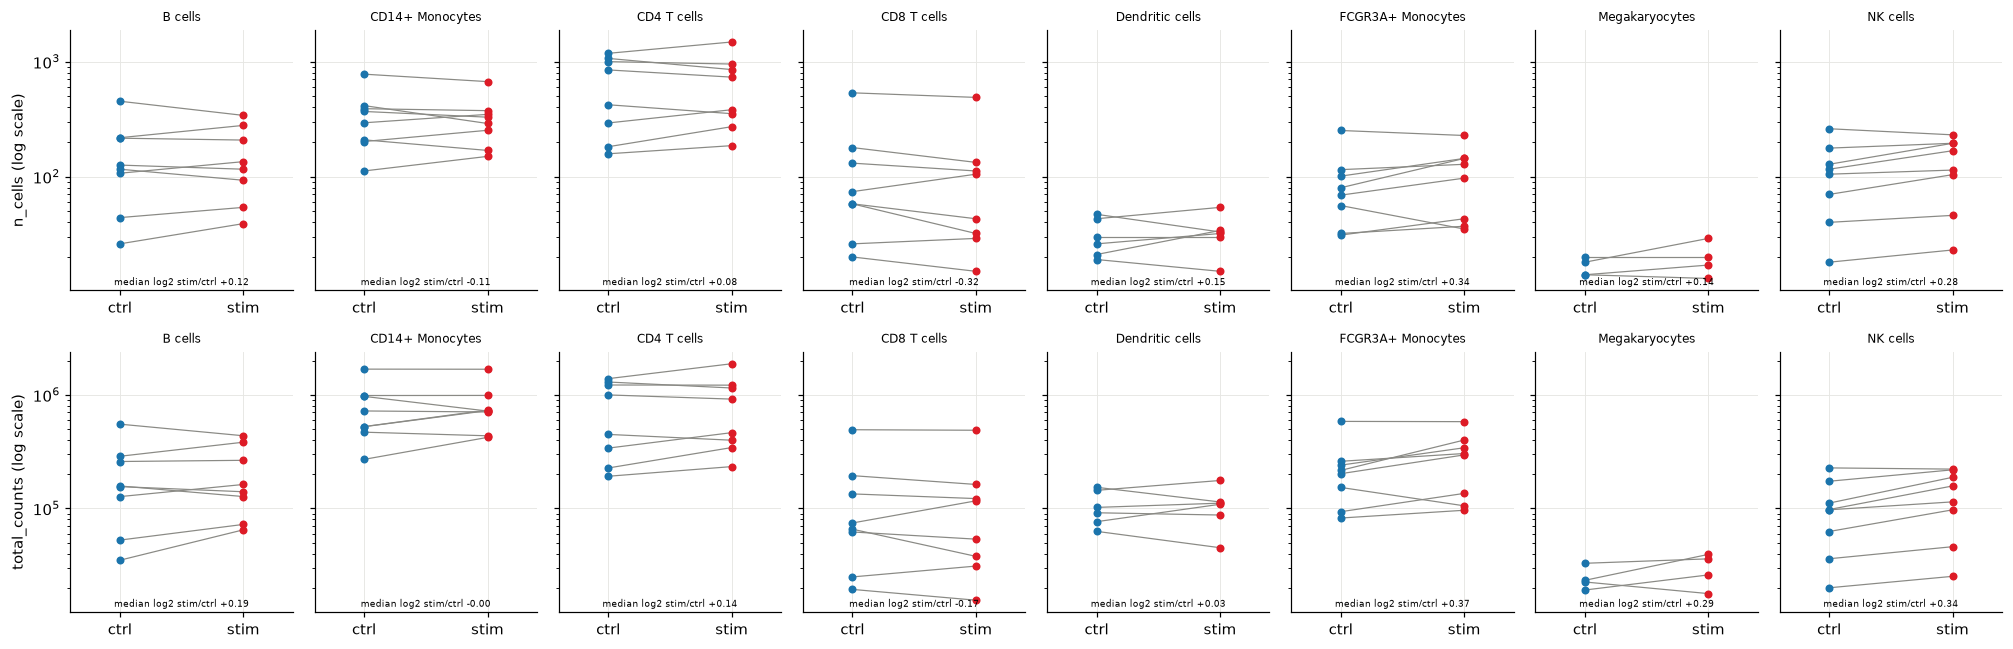

In [4]:
kept = samples[samples["kept"]]
fig, axes = plt.subplots(2, len(CELL_TYPES), figsize=(2.3 * len(CELL_TYPES), 6), sharey="row")
for row, cov in enumerate(["n_cells", "total_counts"]):
    for ax, ct in zip(axes[row], CELL_TYPES):
        wide = kept[kept["cell_type"] == ct].pivot(index="donor", columns="condition", values=cov)[CONDS]
        for _, r in wide.iterrows():
            ax.plot([0, 1], r.values, color="#8a8a85", lw=0.8)
        for i, c in enumerate(CONDS):
            ax.scatter([i] * len(wide), wide[c], color=COND_COLORS[c], s=18, zorder=3)
        ax.set_yscale("log"); ax.set_xticks([0, 1], CONDS); ax.set_xlim(-0.4, 1.4)
        ax.set_title(ct, fontsize=8)
        log_ratio = np.log2(wide[TREATMENT] / wide[CONTROL])
        ax.text(0.5, 0.02, f"median log2 {TREATMENT}/{CONTROL} {log_ratio.median():+.2f}", transform=ax.transAxes, ha="center", fontsize=6)
    axes[row, 0].set_ylabel(cov + " (log scale)")
fig.tight_layout()

## 4. PCA per cell type (kept samples), and distance to the cell type × condition centroid
Space: the DESeq2 `varianceStabilizingTransformation(blind=TRUE)` values written by the R script (genes with baseMean > 1 in that cell type; the same data variance partitioning was fit on), centred, not scaled (decision L2).
Distance = Euclidean distance in that full space from each sample to the mean of its cell type × condition; a ratio to the group's median distance is shown for scale. No automatic flag.

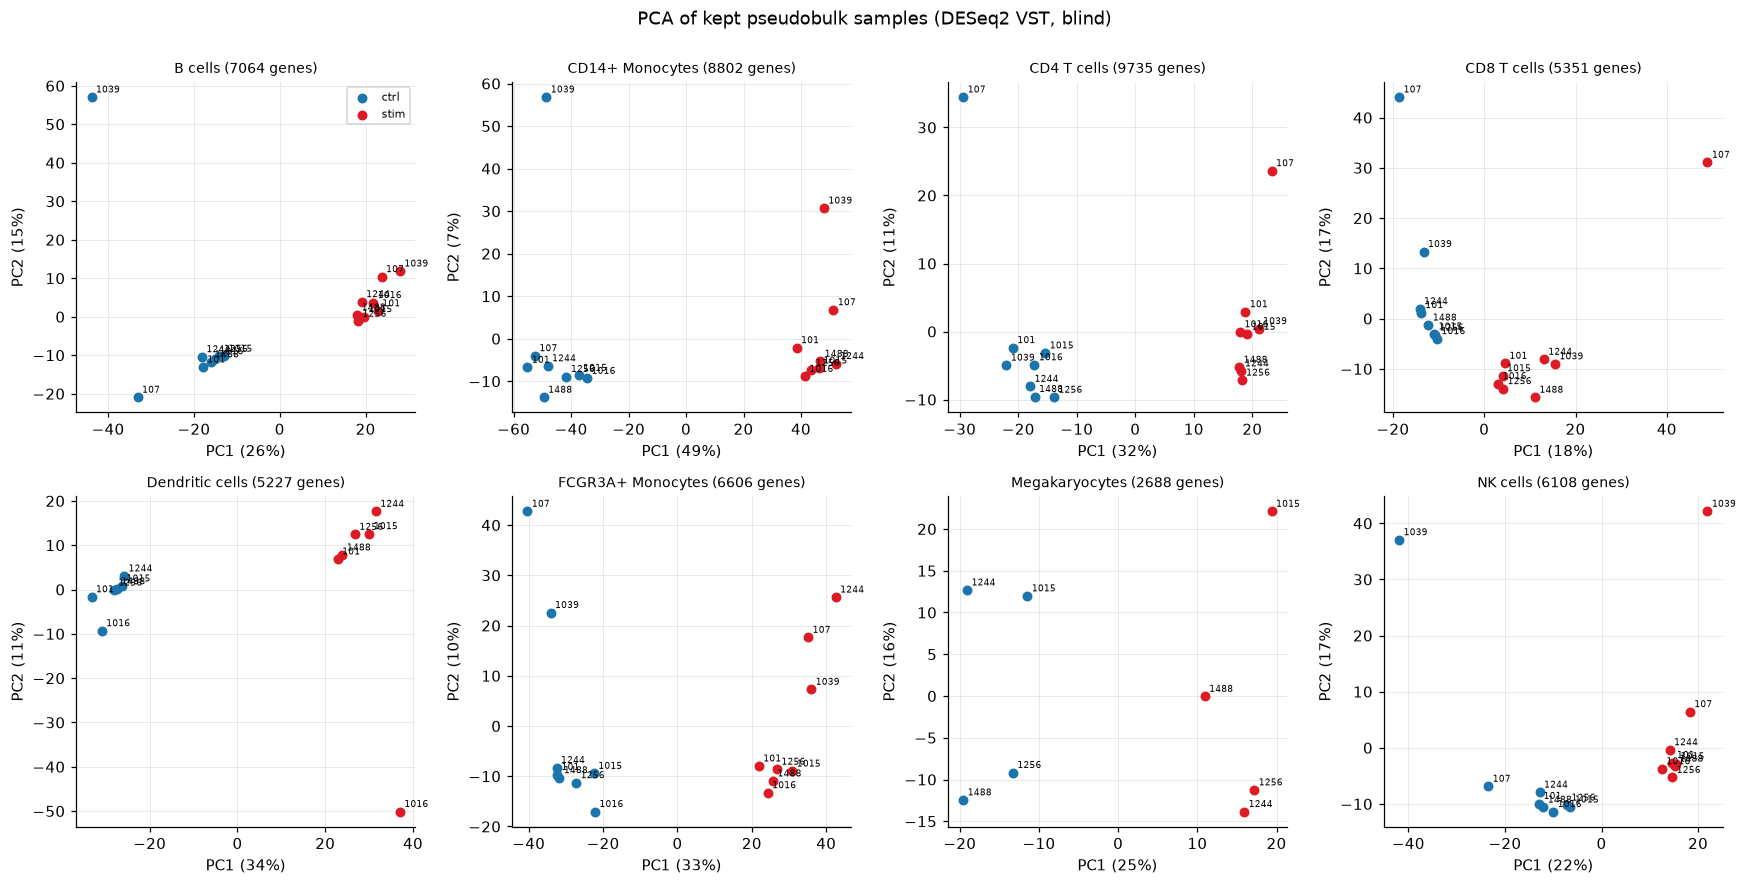

In [5]:
dist_rows = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, ct in zip(axes.ravel(), CELL_TYPES):
    meta = kept[kept["cell_type"] == ct].set_index("sample")
    vs = vst[vst["cell_type"] == ct].pivot(index="gene", columns="sample", values="vst")[meta.index]
    genes = vs.index
    centred = vs.sub(vs.mean(axis=1), axis=0).T.to_numpy()
    u, s, _ = np.linalg.svd(centred, full_matrices=False)
    pcs, var_exp = u * s, s**2 / (s**2).sum()
    for c in CONDS:
        m = (meta["condition"] == c).to_numpy()
        ax.scatter(pcs[m, 0], pcs[m, 1], color=COND_COLORS[c], s=30, label=c)
        for x, y, d in zip(pcs[m, 0], pcs[m, 1], meta.loc[m, "donor"]):
            ax.annotate(d.replace("patient_", ""), (x, y), fontsize=6, xytext=(3, 3), textcoords="offset points")
        group = vs.loc[:, m]
        d_ = np.sqrt(((group.sub(group.mean(axis=1), axis=0)) ** 2).sum(axis=0))
        dist_rows += [{"cell_type": ct, "condition": c, "sample": smp, "donor": meta.loc[smp, "donor"],
                       "distance": dist, "ratio_to_group_median": dist / d_.median()} for smp, dist in d_.items()]
    ax.set_title(f"{ct} ({len(genes)} genes)", fontsize=9)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})"); ax.set_ylabel(f"PC2 ({var_exp[1]:.0%})")
axes[0, 0].legend(fontsize=7)
fig.suptitle("PCA of kept pseudobulk samples (DESeq2 VST, blind)", y=1.0)
fig.tight_layout()

Largest 10 ratios:


,cell_type,condition,sample,donor,distance,ratio_to_group_median
111,NK cells,stim,NK cells|patient_1039|stim,patient_1039,53.574661,2.004715
103,NK cells,ctrl,NK cells|patient_1039|ctrl,patient_1039,56.746211,1.941881
3,B cells,ctrl,B cells|patient_1039|ctrl,patient_1039,65.368809,1.920367
60,CD8 T cells,stim,CD8 T cells|patient_107|stim,patient_107,57.561345,1.804807
52,CD8 T cells,ctrl,CD8 T cells|patient_107|ctrl,patient_107,53.797583,1.710075
36,CD4 T cells,ctrl,CD4 T cells|patient_107|ctrl,patient_107,42.827285,1.656365
89,FCGR3A+ Monocytes,stim,FCGR3A+ Monocytes|patient_1244|stim,patient_1244,59.279292,1.620742
4,B cells,ctrl,B cells|patient_107|ctrl,patient_107,54.396477,1.598028
88,FCGR3A+ Monocytes,stim,FCGR3A+ Monocytes|patient_107|stim,patient_107,58.107564,1.588706
112,NK cells,stim,NK cells|patient_107|stim,patient_107,41.750221,1.562255


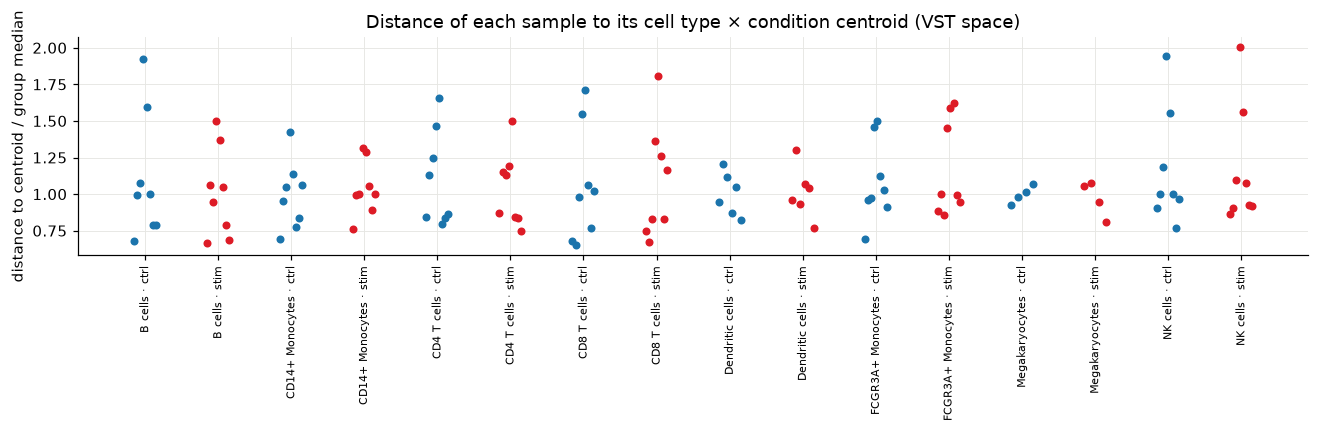

In [6]:
dist = pd.DataFrame(dist_rows)
fig, ax = plt.subplots(figsize=(12, 4))
groups = [(ct, c) for ct in CELL_TYPES for c in CONDS]
for i, (ct, c) in enumerate(groups):
    d = dist[(dist["cell_type"] == ct) & (dist["condition"] == c)]
    ax.scatter(np.full(len(d), i) + np.linspace(-0.15, 0.15, len(d)), d["ratio_to_group_median"], color=COND_COLORS[c], s=18)
ax.set_xticks(range(len(groups)), [f"{ct} · {c}" for ct, c in groups], rotation=90, fontsize=7)
ax.set_ylabel("distance to centroid / group median")
ax.set_title("Distance of each sample to its cell type × condition centroid (VST space)")
fig.tight_layout()
print("Largest 10 ratios:")
display(dist.sort_values("ratio_to_group_median", ascending=False).head(10))

## 5. Variance partitioning per cell type
Fraction of each gene's variance (DESeq2 `varianceStabilizingTransformation(blind=TRUE)`, genes with baseMean > 1) explained by each term of `~ (1|donor) + (1|condition) + log(n_cells) + log(total_counts)`. Each gene's fractions sum to 1.
A4: no numeric rule; the user judges from these plots whether M1b's `~ donor + condition` needs a covariate.

**How to read these violins.** Each violin is all genes in the cell type, and most genes don't respond to IFN-β,
so condition's median share is ~0; for the genes M1b calls DE, condition explains the majority (median 57–83%).
Donor's share of 0 is an artifact: `n_cells` and `total_counts` are almost identical to donor (section 6), so the
variance donor would explain is assigned to them; donor + covariates together give donor's real share (median
~15–34%). The DE model removes donor-level differences, so these covariates don't create stim-vs-ctrl calls.
DE vs non-DE genes are compared in `notebooks/m1b_de.ipynb`, section 8.

In [7]:
print("DESeq2 dispersion trend actually used per cell type (parametric, or local when DESeq2 substituted it):")
display(fits)
print("Genes per cell type after baseMean >", MIN_BASEMEAN)
display(varpart.groupby("cell_type").size().to_frame("genes"))
print("Median variance fraction per term:")
display(varpart.groupby("cell_type")[TERMS].median().round(3))
print("Share of genes where a technical covariate explains > 10% of variance:")
display(varpart.groupby("cell_type")[["log_n_cells", "log_total_counts"]].agg(lambda x: (x > 0.1).mean()).round(3))

DESeq2 dispersion trend actually used per cell type (parametric, or local when DESeq2 substituted it):


,cell_type,fit_type_used
0,B cells,parametric
1,CD14+ Monocytes,parametric
2,CD4 T cells,parametric
3,CD8 T cells,parametric
4,Dendritic cells,parametric
5,FCGR3A+ Monocytes,parametric
6,Megakaryocytes,parametric
7,NK cells,parametric


Genes per cell type after baseMean > 1


,genes
cell_type,
B cells,7064
CD14+ Monocytes,8802
CD4 T cells,9735
CD8 T cells,5351
Dendritic cells,5227
FCGR3A+ Monocytes,6606
Megakaryocytes,2688
NK cells,6108


Median variance fraction per term:


,donor,condition,log_n_cells,log_total_counts,Residuals
cell_type,,,,,
B cells,0.0,0.000,0.082,0.080,0.643
CD14+ Monocytes,0.0,0.092,0.043,0.039,0.564
CD4 T cells,0.0,0.000,0.072,0.071,0.650
CD8 T cells,0.0,0.000,0.066,0.070,0.723
Dendritic cells,0.0,0.000,0.068,0.071,0.563
FCGR3A+ Monocytes,0.0,0.004,0.051,0.051,0.665
Megakaryocytes,0.0,0.000,0.092,0.104,0.518
NK cells,0.0,0.000,0.080,0.073,0.678


Share of genes where a technical covariate explains > 10% of variance:


,log_n_cells,log_total_counts
cell_type,,
B cells,0.424,0.417
CD14+ Monocytes,0.255,0.214
CD4 T cells,0.372,0.366
CD8 T cells,0.331,0.373
Dendritic cells,0.369,0.387
FCGR3A+ Monocytes,0.261,0.269
Megakaryocytes,0.471,0.517
NK cells,0.421,0.388


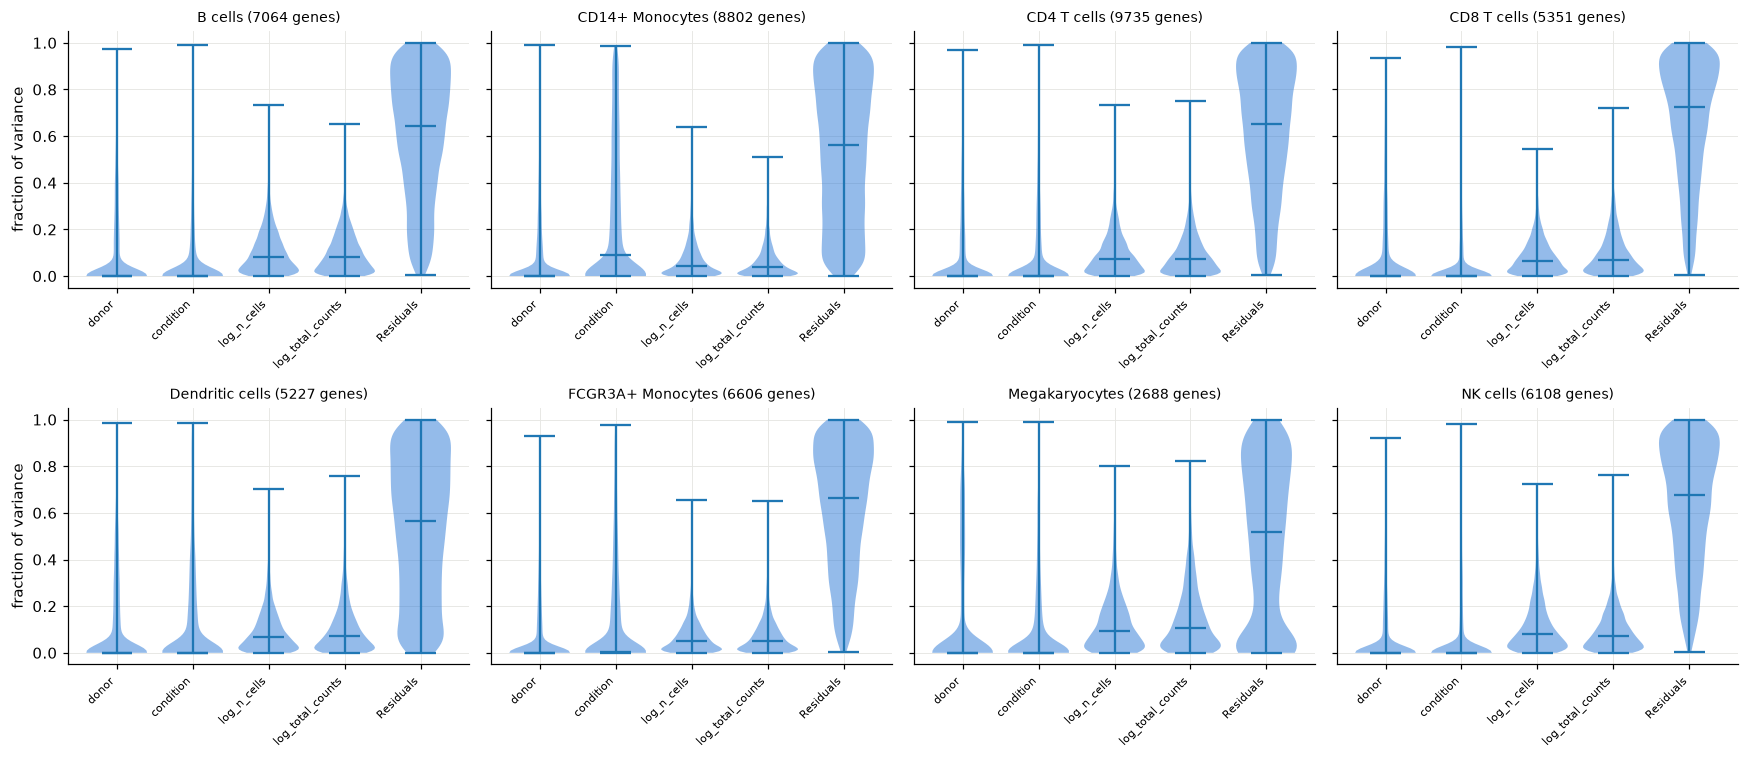

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, ct in zip(axes.ravel(), CELL_TYPES):
    v = varpart[varpart["cell_type"] == ct]
    parts = ax.violinplot([v[t] for t in TERMS], showmedians=True, widths=0.8)
    for body in parts["bodies"]:
        body.set_facecolor("#2a78d6"); body.set_alpha(0.5)
    ax.set_xticks(range(1, len(TERMS) + 1), TERMS, rotation=45, ha="right", fontsize=7)
    ax.set_title(f"{ct} ({len(v)} genes)", fontsize=9)
axes[0, 0].set_ylabel("fraction of variance"); axes[1, 0].set_ylabel("fraction of variance")
fig.tight_layout()

## 6. Collinearity of the model terms (variancePartition `canCorPairs`, kept samples)
Canonical correlation between each pair of terms, per cell type (`R/m1a_cancor.R` → `m1a_cancor.csv`). Values near 1 mean two terms carry the same information, so variance partitioning cannot split variance between them.

term1               condition                        donor                 
term2             log_n_cells log_total_counts log_n_cells log_total_counts
cell_type                                                                  
B cells                 0.037            0.077       0.988            0.980
CD14+ Monocytes         0.024            0.094       0.976            0.964
CD4 T cells             0.040            0.077       0.987            0.987
CD8 T cells             0.078            0.033       0.988            0.990
Dendritic cells         0.076            0.008       0.914            0.941
FCGR3A+ Monocytes       0.121            0.170       0.966            0.958
Megakaryocytes          0.305            0.312       0.847            0.801
NK cells                0.130            0.189       0.985            0.975

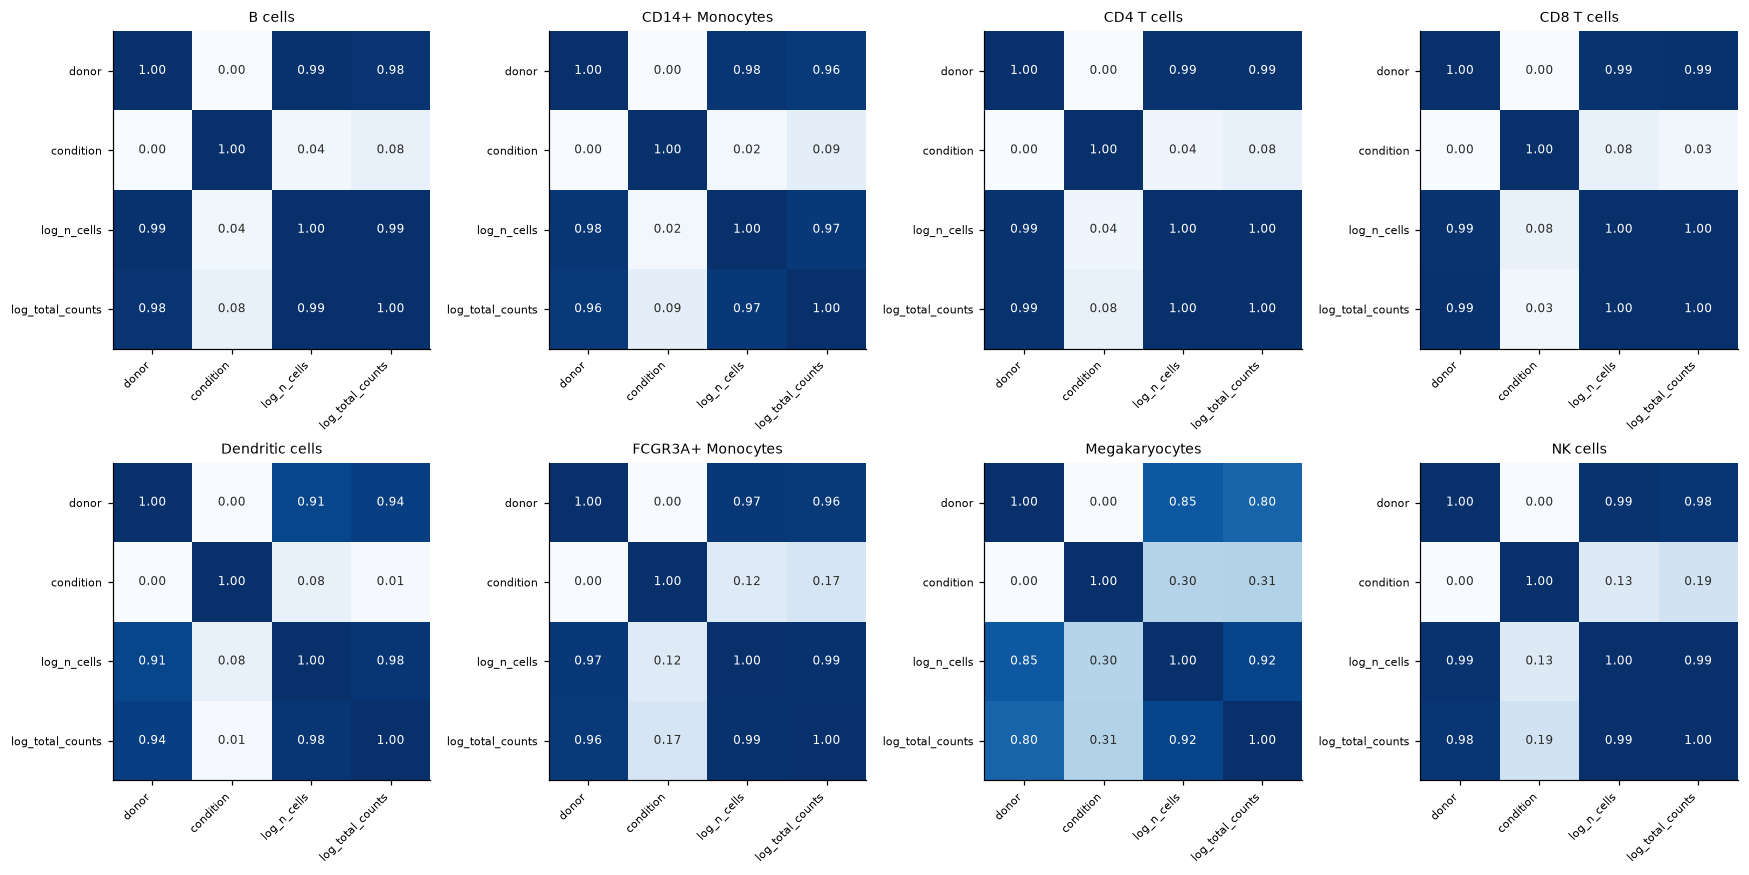

In [9]:
cancor = pd.read_csv(PROC / "m1a_cancor.csv")
CC_TERMS = ["donor", "condition", "log_n_cells", "log_total_counts"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, ct in zip(axes.ravel(), CELL_TYPES):
    m = cancor[cancor["cell_type"] == ct].pivot(index="term1", columns="term2", values="cancor").loc[CC_TERMS, CC_TERMS]
    ax.imshow(m.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CC_TERMS)):
        for j in range(len(CC_TERMS)):
            ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if m.iat[i, j] > 0.6 else "#2b2b28")
    ax.set_xticks(range(len(CC_TERMS)), CC_TERMS, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(len(CC_TERMS)), CC_TERMS, fontsize=7)
    ax.set_title(ct, fontsize=9); ax.grid(False)
fig.tight_layout()
display(cancor[cancor["term1"].isin(["donor", "condition"]) & cancor["term2"].isin(["log_n_cells", "log_total_counts"])]
        .pivot_table(index="cell_type", columns=["term1", "term2"], values="cancor").round(3))